In [1]:

import warnings
warnings.filterwarnings("ignore")

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.metrics import mean_squared_error, mean_absolute_error

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:

df = pd.read_csv("airline_passengers_monthly.csv")

# Convert Month into datetime and set it as the index
df["Month"] = pd.to_datetime(df["Month"])
df = df.sort_values("Month").set_index("Month")

# Keep the target column as a numeric series
df["Passengers"] = pd.to_numeric(df["Passengers"], errors="coerce")
df = df[["Passengers"]].dropna()

# Set monthly frequency
df = df.asfreq("MS")

print("First five rows:")
display(df.head())

print("\nDataset information:")
print(df.info())
print("\nMissing values:")
print(df.isnull().sum())
print("\nNumber of observations:", len(df))

First five rows:


,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121



Dataset information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Freq: MS
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Passengers  144 non-null    int64
dtypes: int64(1)
memory usage: 2.2 KB
None

Missing values:
Passengers    0
dtype: int64

Number of observations: 144


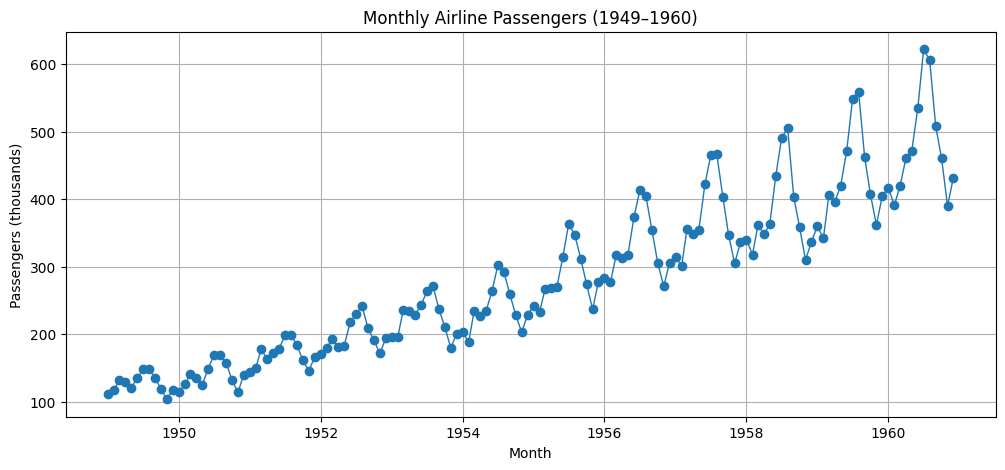

In [3]:
plt.figure()
plt.plot(df.index, df["Passengers"], marker="o", linewidth=1)
plt.title("Monthly Airline Passengers (1949–1960)")
plt.xlabel("Month")
plt.ylabel("Passengers (thousands)")
plt.show()

In [4]:
adf_result = adfuller(df["Passengers"])

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:")
for key, value in adf_result[4].items():
    print(f"  {key}: {value}")

if adf_result[1] < 0.05:
    print("\nConclusion: The series is stationary (at 5% significance level).")
else:
    print("\nConclusion: The series is non-stationary (at 5% significance level).")

ADF Statistic: 0.8153688792060482
p-value: 0.991880243437641
Critical Values:
  1%: -3.4816817173418295
  5%: -2.8840418343195267
  10%: -2.578770059171598

Conclusion: The series is non-stationary (at 5% significance level).


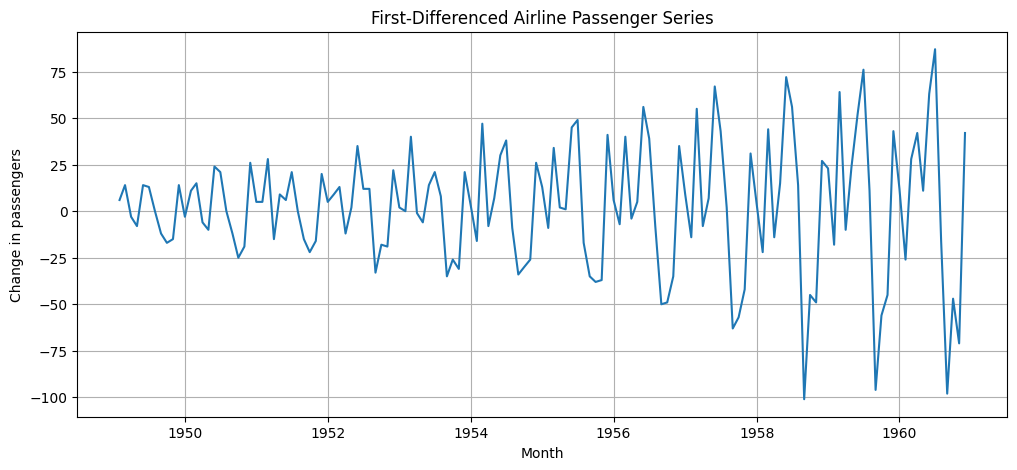

ADF statistic after first differencing: -2.8292668241699994
p-value after first differencing: 0.0542132902838255


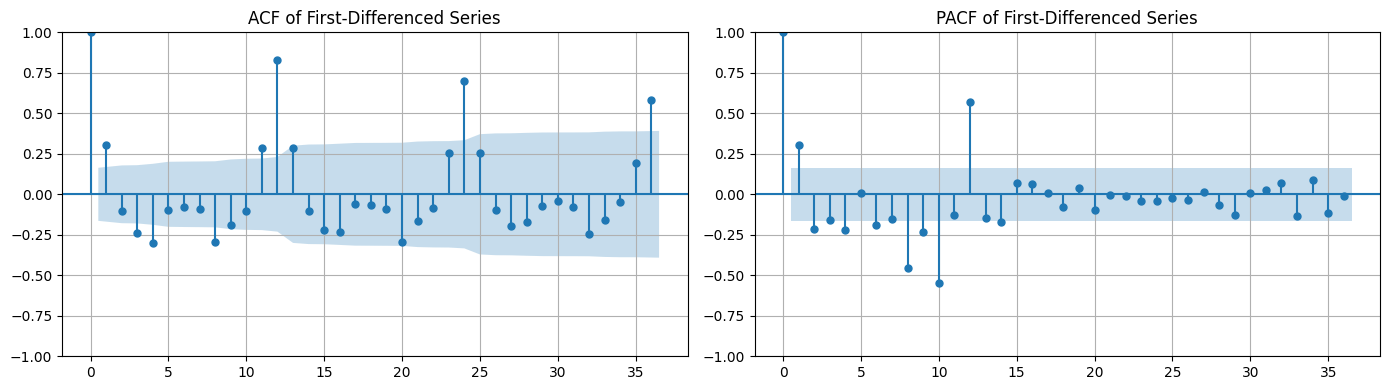

In [5]:
# First difference helps remove the trend
first_diff = df["Passengers"].diff().dropna()

plt.figure()
plt.plot(first_diff.index, first_diff)
plt.title("First-Differenced Airline Passenger Series")
plt.xlabel("Month")
plt.ylabel("Change in passengers")
plt.show()

adf_diff = adfuller(first_diff)
print("ADF statistic after first differencing:", adf_diff[0])
print("p-value after first differencing:", adf_diff[1])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(first_diff, lags=36, ax=axes[0])
plot_pacf(first_diff, lags=36, method="ywm", ax=axes[1])
axes[0].set_title("ACF of First-Differenced Series")
axes[1].set_title("PACF of First-Differenced Series")
plt.tight_layout()
plt.show()

Training observations: 115
Testing observations: 29
Training period: 1949-01-01 to 1958-07-01
Testing period: 1958-08-01 to 1960-12-01


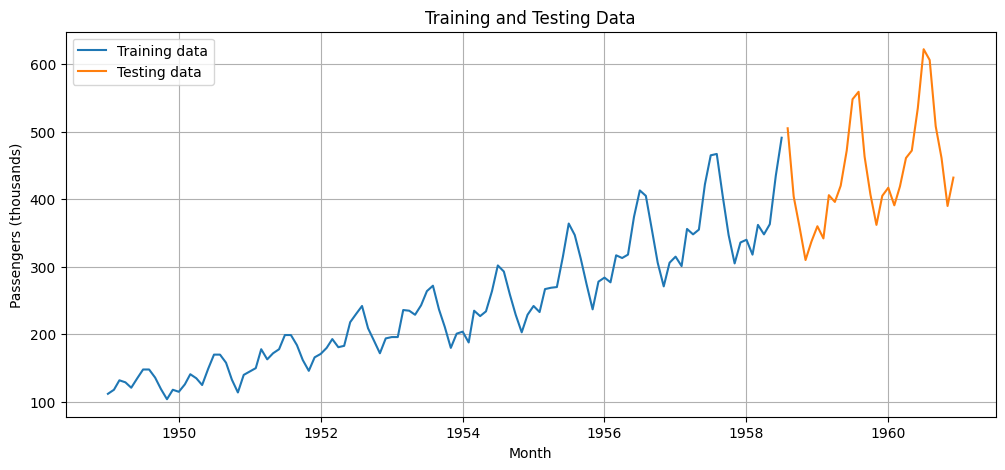

In [6]:
split_point = int(len(df) * 0.80)

train = df["Passengers"].iloc[:split_point]
test = df["Passengers"].iloc[split_point:]

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Training period:", train.index.min().date(), "to", train.index.max().date())
print("Testing period:", test.index.min().date(), "to", test.index.max().date())

plt.figure()
plt.plot(train.index, train, label="Training data")
plt.plot(test.index, test, label="Testing data")
plt.title("Training and Testing Data")
plt.xlabel("Month")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.show()

# Store forecasts and evaluation results
forecasts = {}
results = []

def evaluate_model(actual, predicted, model_name):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100

    row = {
        "Model": model_name,
        "RMSE": rmse,
        "MAE": mae,
        "MAPE (%)": mape
    }
    return row

Selected AR lag: 12
                            AutoReg Model Results                             
Dep. Variable:             Passengers   No. Observations:                  102
Model:                    AutoReg(12)   Log Likelihood                -364.590
Method:               Conditional MLE   S.D. of innovations              8.632
Date:                Sat, 14 Nov 2026   AIC                            757.180
Time:                        21:09:43   BIC                            793.929
Sample:                            12   HQIC                           772.061
                                  114                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const              6.3036      1.937      3.255      0.001       2.507      10.100
Passengers.L1     -0.1400      0.070     -1.987      0.047      -0.278      -0.002
Passengers.L2   

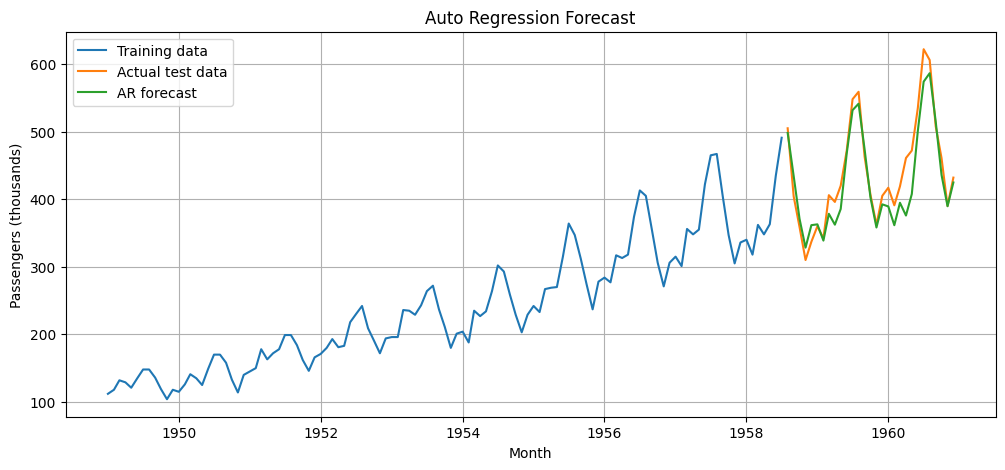

In [7]:
train_diff = train.diff().dropna().reset_index(drop=True)

best_ar_lag = None
best_ar_aic = np.inf

for lag in range(1, min(13, len(train_diff) // 3)):
    try:
        fitted = AutoReg(train_diff, lags=lag, trend="c").fit()
        if fitted.aic < best_ar_aic:
            best_ar_aic = fitted.aic
            best_ar_lag = lag
    except Exception:
        continue

if best_ar_lag is None:
    raise ValueError("Could not fit the AutoReg model. Check the training data.")

ar_fit = AutoReg(train_diff, lags=best_ar_lag, trend="c").fit()
ar_diff_forecast = ar_fit.predict(
    start=len(train_diff),
    end=len(train_diff) + len(test) - 1
)

# Convert predicted changes into predicted passenger levels
ar_forecast_values = train.iloc[-1] + np.cumsum(np.asarray(ar_diff_forecast))
ar_forecast = pd.Series(ar_forecast_values, index=test.index)

print("Selected AR lag:", best_ar_lag)
print(ar_fit.summary())

forecasts["Auto Regression"] = ar_forecast
results.append(evaluate_model(test, ar_forecast, "Auto Regression"))

plt.figure()
plt.plot(train.index, train, label="Training data")
plt.plot(test.index, test, label="Actual test data")
plt.plot(test.index, ar_forecast, label="AR forecast")
plt.title("Auto Regression Forecast")
plt.xlabel("Month")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.show()

C:\Users\Activecanvas\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Activecanvas\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Activecanvas\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\Activecanvas\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = sel

Selected ARMA order (p, q): (3, 3)
                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  114
Model:                 ARIMA(3, 0, 3)   Log Likelihood                -503.640
Date:                Sat, 14 Nov 2026   AIC                           1023.281
Time:                        21:10:00   BIC                           1045.170
Sample:                             0   HQIC                          1032.164
                                - 114                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.3734      0.927      2.560      0.010       0.557       4.190
ar.L1          0.9333      0.091     10.226      0.000       0.754       1.112
ar.L2          0.

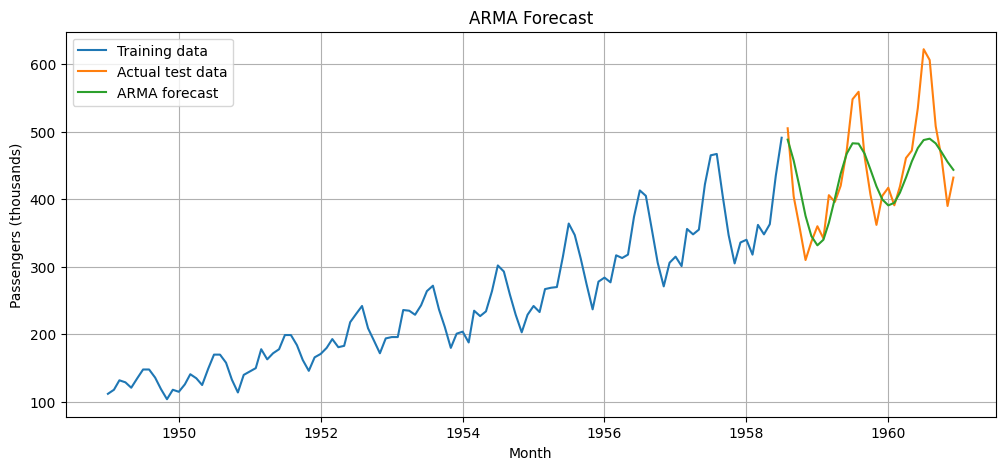

In [8]:
train_arma = train.diff().dropna().reset_index(drop=True)

best_arma_order = None
best_arma_aic = np.inf

for p, q in itertools.product(range(4), range(4)):
    if p == 0 and q == 0:
        continue
    try:
        fitted = ARIMA(train_arma, order=(p, 0, q)).fit()
        if fitted.aic < best_arma_aic:
            best_arma_aic = fitted.aic
            best_arma_order = (p, q)
    except Exception:
        continue

if best_arma_order is None:
    raise ValueError("Could not fit an ARMA model. Check the training data.")

arma_fit = ARIMA(
    train_arma,
    order=(best_arma_order[0], 0, best_arma_order[1])
).fit()

arma_diff_forecast = arma_fit.forecast(steps=len(test))
arma_forecast_values = train.iloc[-1] + np.cumsum(np.asarray(arma_diff_forecast))
arma_forecast = pd.Series(arma_forecast_values, index=test.index)

print("Selected ARMA order (p, q):", best_arma_order)
print(arma_fit.summary())

forecasts["ARMA"] = arma_forecast
results.append(evaluate_model(test, arma_forecast, "ARMA"))

plt.figure()
plt.plot(train.index, train, label="Training data")
plt.plot(test.index, test, label="Actual test data")
plt.plot(test.index, arma_forecast, label="ARMA forecast")
plt.title("ARMA Forecast")
plt.xlabel("Month")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.show()

C:\Users\Activecanvas\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Activecanvas\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Activecanvas\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\Activecanvas\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Selected ARIMA order (p, d, q): (3, 1, 3)
                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  115
Model:                 ARIMA(3, 1, 3)   Log Likelihood                -507.430
Date:                Sat, 14 Nov 2026   AIC                           1028.861
Time:                        21:10:44   BIC                           1048.014
Sample:                             0   HQIC                          1036.634
                                - 115                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9585      0.095     10.078      0.000       0.772       1.145
ar.L2          0.2874      0.140      2.048      0.041       0.012       0.562
ar.L3     

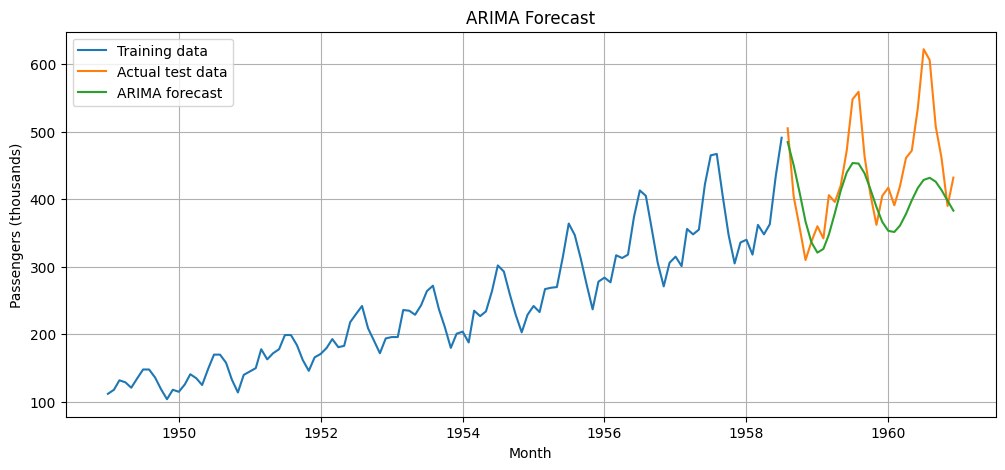

In [9]:
train_arima = train.reset_index(drop=True)

best_arima_order = None
best_arima_aic = np.inf

# Search ARIMA(p, 1, q) models using AIC
for p, q in itertools.product(range(4), range(4)):
    try:
        fitted = ARIMA(train_arima, order=(p, 1, q)).fit()
        if fitted.aic < best_arima_aic:
            best_arima_aic = fitted.aic
            best_arima_order = (p, 1, q)
    except Exception:
        continue

if best_arima_order is None:
    raise ValueError("Could not fit an ARIMA model. Check the training data.")

arima_fit = ARIMA(train_arima, order=best_arima_order).fit()
arima_forecast_values = arima_fit.forecast(steps=len(test))
arima_forecast = pd.Series(np.asarray(arima_forecast_values), index=test.index)

print("Selected ARIMA order (p, d, q):", best_arima_order)
print(arima_fit.summary())

forecasts["ARIMA"] = arima_forecast
results.append(evaluate_model(test, arima_forecast, "ARIMA"))

plt.figure()
plt.plot(train.index, train, label="Training data")
plt.plot(test.index, test, label="Actual test data")
plt.plot(test.index, arima_forecast, label="ARIMA forecast")
plt.title("ARIMA Forecast")
plt.xlabel("Month")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.show()

Selected SARIMA order: (1, 1, 1)
Selected seasonal order: (1, 1, 1, 12)
                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  115
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -323.801
Date:                            Sat, 14 Nov 2026   AIC                            657.601
Time:                                    21:11:00   BIC                            669.988
Sample:                                         0   HQIC                           662.592
                                            - 115                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8224      0.184     -4.46

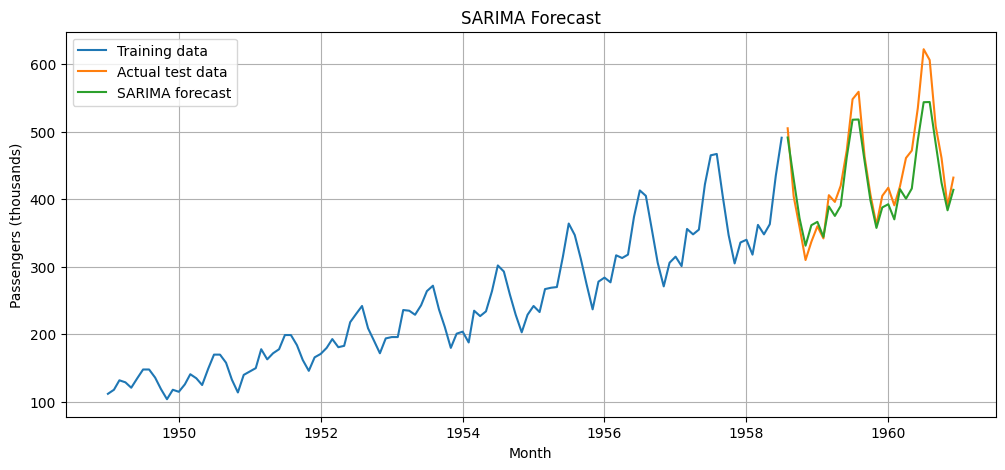

In [10]:
train_sarima = train.reset_index(drop=True)

# Small parameter search to keep execution manageable
pdq = list(itertools.product(range(2), [1], range(2)))
seasonal_pdq = list(itertools.product(range(2), [1], range(2), [12]))

best_sarima_order = None
best_seasonal_order = None
best_sarima_aic = np.inf

for order in pdq:
    for seasonal_order in seasonal_pdq:
        try:
            fitted = SARIMAX(
                train_sarima,
                order=order,
                seasonal_order=seasonal_order,
                enforce_stationarity=False,
                enforce_invertibility=False
            ).fit(disp=False)

            if fitted.aic < best_sarima_aic:
                best_sarima_aic = fitted.aic
                best_sarima_order = order
                best_seasonal_order = seasonal_order
        except Exception:
            continue

if best_sarima_order is None:
    raise ValueError("Could not fit a SARIMA model. Check the training data.")

sarima_fit = SARIMAX(
    train_sarima,
    order=best_sarima_order,
    seasonal_order=best_seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_forecast_values = sarima_fit.forecast(steps=len(test))
sarima_forecast = pd.Series(np.asarray(sarima_forecast_values), index=test.index)

print("Selected SARIMA order:", best_sarima_order)
print("Selected seasonal order:", best_seasonal_order)
print(sarima_fit.summary())

forecasts["SARIMA"] = sarima_forecast
results.append(evaluate_model(test, sarima_forecast, "SARIMA"))

plt.figure()
plt.plot(train.index, train, label="Training data")
plt.plot(test.index, test, label="Actual test data")
plt.plot(test.index, sarima_forecast, label="SARIMA forecast")
plt.title("SARIMA Forecast")
plt.xlabel("Month")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.show()

In [11]:
comparison = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)

print("Model performance comparison:")
display(comparison)

best_model = comparison.iloc[0]["Model"]
print("Best model based on RMSE:", best_model)

Model performance comparison:


,Model,RMSE,MAE,MAPE (%)
0,Auto Regression,28.900386,21.911439,4.935667
1,SARIMA,31.787297,25.268045,5.427511
2,ARMA,49.389474,36.295785,7.987477
3,ARIMA,72.539666,56.328357,11.927249


Best model based on RMSE: Auto Regression


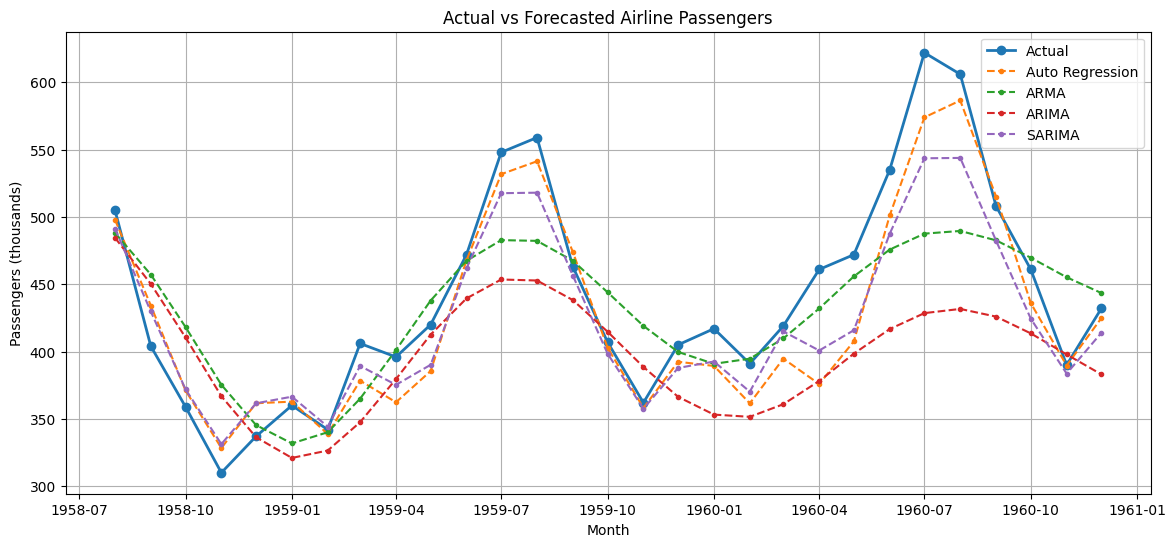

In [12]:
plt.figure(figsize=(14, 6))
plt.plot(test.index, test, marker="o", linewidth=2, label="Actual")

for model_name, forecast in forecasts.items():
    plt.plot(test.index, forecast, marker=".", linestyle="--", label=model_name)

plt.title("Actual vs Forecasted Airline Passengers")
plt.xlabel("Month")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.show()

C:\Users\Activecanvas\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Best SARIMA: (1, 1, 1)
Best seasonal order: (1, 1, 1, 12)
Best AIC: 657.6013462972924
                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  115
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -323.801
Date:                            Sat, 14 Nov 2026   AIC                            657.601
Time:                                    21:20:03   BIC                            669.988
Sample:                                         0   HQIC                           662.592
                                            - 115                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8224      0

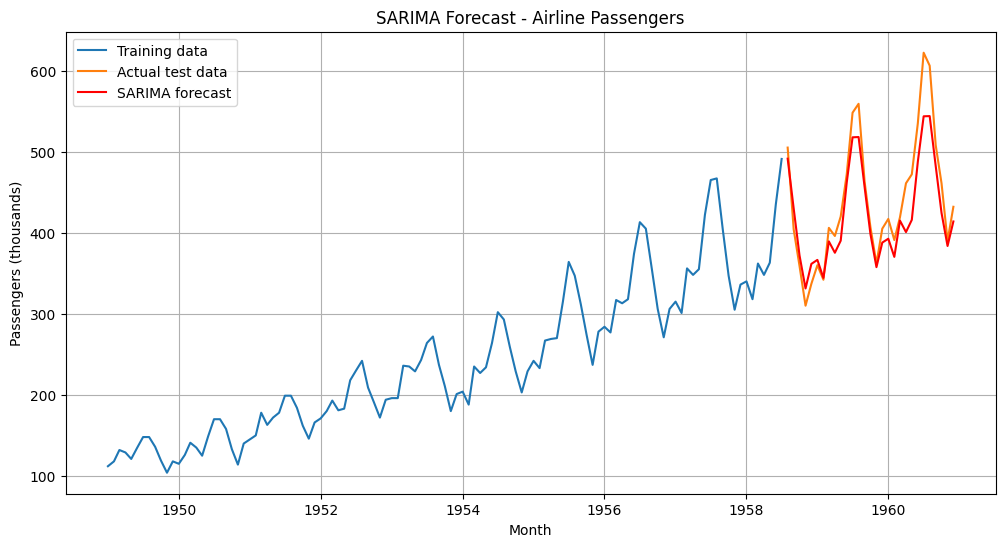

In [13]:

# SARIMA MODEL

train_sarima = train.reset_index(drop=True)

p = d = q = range(0, 2)

pdq = list(itertools.product(p, d, q))

seasonal_pdq = [
    (x[0], x[1], x[2], 12)
    for x in itertools.product(p, d, q)
]

best_aic = np.inf
best_pdq = None
best_seasonal_pdq = None

for param in pdq:
    for param_seasonal in seasonal_pdq:
        try:
            temp_model = SARIMAX(
                train_sarima,
                order=param,
                seasonal_order=param_seasonal,
                enforce_invertibility=False,
                enforce_stationarity=False
            )

            temp_results = temp_model.fit(disp=False)

            if temp_results.aic < best_aic:
                best_aic = temp_results.aic
                best_pdq = param
                best_seasonal_pdq = param_seasonal

        except Exception:
            continue

print("Best SARIMA:", best_pdq)
print("Best seasonal order:", best_seasonal_pdq)
print("Best AIC:", best_aic)

# Fit the best SARIMA model
sarima_model = SARIMAX(
    train_sarima,
    order=best_pdq,
    seasonal_order=best_seasonal_pdq,
    enforce_invertibility=False,
    enforce_stationarity=False
)

sarima_fit = sarima_model.fit(disp=False)

# Forecast the test period
sarima_forecast = sarima_fit.predict(
    start=len(train_sarima),
    end=len(train_sarima) + len(test) - 1,
    dynamic=False
)

sarima_forecast = pd.Series(
    np.asarray(sarima_forecast),
    index=test.index
)

print(sarima_fit.summary())

# Store forecast and evaluation
forecasts["SARIMA"] = sarima_forecast

results.append(
    evaluate_model(test, sarima_forecast, "SARIMA")
)

# Plot results
plt.figure(figsize=(12, 6))
plt.plot(train.index, train, label="Training data")
plt.plot(test.index, test, label="Actual test data")
plt.plot(test.index, sarima_forecast, color="red", label="SARIMA forecast")

plt.title("SARIMA Forecast - Airline Passengers")
plt.xlabel("Month")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.show()
